<a href="https://colab.research.google.com/github/jelenavasic009-png/dsb_capstone/blob/main/notebooks/01_EDA_JelenaVasic_capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Maritime Vignette Analytics & Smart Inspection System**
*Revenue Analysis, Tariff Modeling & Automated Compliance Detection*
>
> **Project Overview**  

>### Project Overview
This project analyzes 26,764 marine vignette transactions across six regional port branches of the Ministry of Maritime Affairs (2021–2025). Using Python and machine learning (`pandas`, `scikit-learn`, `Prophet`, and `Plotly`), we clean the dataset, forecast seasonal revenue, model tariff structures, and build an **automated inspection & anomaly detection system** to identify **vessel length discrepancies** and **suspected illegal chartering ("grey charter")**.


In [ ]:
# Core data manipulation and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px



---

### **Step 1: Data Sourcing & Initial Loading**

> When starting a data science project, the first step is to bring the raw data into our Python environment. We use the `pandas` library to read an Excel spreadsheet and inspect its structural outline.
> * `pd.read_excel()`: This function opens the Excel sheet and converts it into a DataFrame (a table structured with rows and columns, similar to a spreadsheet).
> * `df.head(10)`: Displays the top 10 records. This helps us manually verify that headers and data fields are aligned correctly.
> * `df.shape`: Returns a tuple containing the total number of rows and columns, letting us know the scale of our data.
>
>

## 📖 Data Dictionary
To ensure complete transparency and clear understanding of the features used throughout this Exploratory Data Analysis (EDA) and feature engineering pipeline, the dataset variables are separated into **original raw features** and **engineered features**:

### 1. Original Dataset Features (11 Columns)
| Column Name | Data Type | Description & Business Purpose |
| :--- | :--- | :--- |
| **Vignette serial number** | `object` | Unique identification number assigned to each issued vignette transaction. |
| **Name of the vessel** | `object` | Registered name of the maritime vessel (missing values imputed as `'Unknown Vessel'`). |
| **Length of the vessel** | `float64` | Total length of the vessel in meters, used for size categorization and segmentation. |
| **Purpose of use** | `object` | Intended purpose or category of utilization (e.g., `personal`, `chartering`). |
| **Valid from** | `datetime64` | Start date and time when the vignette becomes active and valid. |
| **Valid until** | `datetime64` | Expiration date and time of the vignette validity period. |
| **Duration** | `object` | Duration type or validity span of the vignette (e.g., `24, h`, `7, d`, `6, M`, `1, y`). |
| **Issued by** | `object` | Regional port branch office responsible for issuance (e.g., Tivat, Zelenika, Bar). |
| **Price excluding tax €** | `float64` | Base financial cost of the vignette excluding applicable taxes. |
| **Tax €** | `int64` | Fixed tax amount applied to the vignette transaction. |
| **Total price €** | `float64` | Final gross transaction price paid including tax (used for revenue analysis). |

### 2. Engineered Features (Created During Analysis)
| Column Name | Data Type | Description & Business Purpose |
| :--- | :--- | :--- |
| **Year** | `int` | Extracted standalone year feature derived from `'Valid from'` for chronological analysis. |
| **Month** | `int` | Extracted calendar month number (`1` to `12`) used to identify monthly patterns. |
| **Season** | `object` | Categorical seasonal flag mapped from month numbers (`Spring`, `Summer`, `Autumn`, `Winter`). |
| **Clean_Year** | `int` | Standardized integer year format utilized specifically for vessel loyalty tracking. |
| **Revenue_in_Thousands** | `float64` | Scaled total price metric representing revenue in thousands of euros for charts. |
| **PCA1 & PCA2** | `float64` | Principal components generated via `StandardScaler` and `PCA` dimensionality reduction. |
| **Is_Covid_Period** | `int` | Binary indicator flag (`1` for years 2020–2022, `0` otherwise) isolating pandemic shifts. |

In [2]:
data_path = "../data/raw/Baza podataka 5 godina.xlsx"
df = pd.read_excel(data_path)
print("Baza podataka za 5 godina")

Baza podataka za 5 godina


In [3]:

# Preview the first 10 rows to understand the structure
print("\n--- First 10 Rows of the Dataset ---")
df.head(10)


--- First 10 Rows of the Dataset ---


,Vignette serial number,Name of the vessel,Length of the vessel,Purpose of use,Valid from,Valid until,Duration,Issued by,Price excluding tax €,Tax €,Total price €
0,2020202103889,MELODY,16.80,personal,2021-01-04,2021-01-05,"24, h",Bar,16.80,2,18.80
1,2020202102390,QUIEN SABE,13.35,personal,2021-01-10,2021-01-10,"24, h",Tivat,40.05,2,42.05
2,2020202103890,GRETONY,16.80,personal,2021-01-13,2021-01-20,"7, d",Bar,33.60,2,35.60
3,2020202100414,KAY AND DUKE,15.24,personal,2021-01-13,2021-07-13,"6, M",Zelenika,381.00,2,383.00
4,2020202102391,ODYSSEY,23.20,personal,2021-01-15,2021-01-16,"24, h",Tivat,23.20,2,25.20
5,2020202102393,ANNA MARIA I,17.20,personal,2021-01-16,2021-01-17,"24, h",Tivat,51.60,2,53.60
6,2020202102392,MURMUR,9.99,personal,2021-01-16,2021-01-23,"7, d",Tivat,19.98,2,21.98
7,2020202100416,AURORA,11.94,personal,2021-01-17,2021-01-18,"24, h",Zelenika,11.94,2,13.94
8,2020202100415,VONGOLA,11.90,personal,2021-01-17,2021-01-18,"24, h",Zelenika,11.90,2,13.90
9,2020202100417,PIRAT,4.40,personal,2021-01-18,2021-07-18,"6, M",Zelenika,17.60,2,19.60


In [4]:
# Check the total dimensions (Rows, Columns)
print("\n--- Dataset Dimensions (Rows, Columns) ---")
print(df.shape)


--- Dataset Dimensions (Rows, Columns) ---
(26764, 11)



---

### **Step 2: Structural Audit & Descriptive Statistics**

> Before performing calculations, we must understand the data types of our columns (e.g., whether a column contains text, integers, or dates) and look at basic statistical summaries.
> * `df.info()`: Reveals if columns like `Valid from` are recognized as proper text objects (`object`) or date formats. It also counts how many entries are filled vs. empty.
> * `df.describe()`: Calculates the mean, minimum, maximum, and standard deviation for structural columns like `Length of the vessel` and `Total price €`.
> * `mean`: The mathematical average.
> * `std`: Standard deviation (how spread out the values are from the average).
> * `min / max`: The lowest and highest values in that specific column.
> * `25%, 50%, 75%`: Percentiles showing distribution boundaries.
>
>
>
>

In [5]:
# Check data types and non-null counts
print("--- Dataset Structural Information ---")
df.info()


--- Dataset Structural Information ---
<class 'pandas.DataFrame'>
RangeIndex: 26764 entries, 0 to 26763
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Vignette serial number  26764 non-null  object        
 1   Name of the vessel      26758 non-null  object        
 2   Length of the vessel    26764 non-null  float64       
 3   Purpose of use          26764 non-null  str           
 4   Valid from              26764 non-null  datetime64[us]
 5   Valid until             26764 non-null  datetime64[us]
 6   Duration                26761 non-null  str           
 7   Issued by               26764 non-null  str           
 8   Price excluding tax €   26764 non-null  float64       
 9   Tax €                   26764 non-null  int64         
 10  Total price €           26764 non-null  float64       
dtypes: datetime64[us](2), float64(3), int64(1), object(2), str(3)
memory usage: 2.

In [6]:
# Basic descriptive statistics for numerical columns
df.describe()

,Length of the vessel,Valid from,Valid until,Price excluding tax €,Tax €,Total price €
count,26764.000000,26764,26764,26764.000000,26764.0,26764.000000
mean,15.376766,2023-08-18 17:04:28.480047,2023-10-17 04:39:04.761620,135.848941,2.0,137.848941
min,2.000000,2021-01-04 00:00:00,2021-01-05 00:00:00,1.660000,2.0,3.660000
25%,8.447500,2022-06-28 00:00:00,2022-08-15 00:00:00,22.600000,2.0,24.600000
50%,12.950000,2023-08-01 00:00:00,2023-09-28 00:00:00,66.570000,2.0,68.570000
75%,16.820000,2024-09-01 00:00:00,2024-11-18 00:00:00,176.780000,2.0,178.780000
max,162.500000,2026-01-20 00:00:00,2026-12-30 00:00:00,5700.000000,2.0,5702.000000
std,12.265739,NaN,NaN,193.603423,0.0,193.603423



---

### **Step 3: Data Cleansing & Missing Value Handling**

> Real-world data is rarely perfect. Spreadsheets often contain empty rows, total summary blocks at the bottom, or mismatched data fields that can disrupt machine learning algorithms.
> * `df.isnull().sum()`: Searches the entire table for empty cells (`NaN`) and totals them up for every column, making it easy to identify data gaps.
> * `df.dropna(subset=[...])`: Drops rows that lack essential identifier information. This removes generic total columns or incomplete test entries from the bottom of spreadsheets.
>
>

In [7]:
# Check the total count of missing (NaN) values per column
print("\n--- Count of Missing Values Per Column ---")
missing_summary = df.isnull().sum()
print(missing_summary)

# Fill missing values instead of dropping rows
df['Name of the vessel'] = df['Name of the vessel'].fillna('Unknown Vessel')

df['Duration'] = df['Duration'].fillna('Unknown Duration')

print("\nSuccessfully filled missing values without dropping rows!")



--- Count of Missing Values Per Column ---
Vignette serial number    0
Name of the vessel        6
Length of the vessel      0
Purpose of use            0
Valid from                0
Valid until               0
Duration                  3
Issued by                 0
Price excluding tax €     0
Tax €                     0
Total price €             0
dtype: int64

Successfully filled missing values without dropping rows!



---

### **Checking for Outliers and Data Anomalies**

> Before proceeding with analysis, we perform a quick quality check to ensure there are no illogical dates (e.g., expiration before start date), negative/zero prices, or invalid vessel lengths in the dataset.




In [8]:
# Check if 'Valid until' is anywhere earlier than 'Valid from'
invalid_dates = df[df['Valid until'] < df['Valid from']]
print("Number of illogical dates:", len(invalid_dates))

# Check if there are any prices less than or equal to zero
invalid_prices = df[df['Total price €'] <= 0]
print("Number of invalid prices:", len(invalid_prices))

# Check if there are any vessel lengths less than or equal to zero
invalid_lengths = df[df['Length of the vessel'] <= 0]
print("Number of invalid vessel lengths:", len(invalid_lengths))

Number of illogical dates: 0
Number of invalid prices: 0
Number of invalid vessel lengths: 0



---

### **Step 4: Categorical Grouping & Business Insights**

> To understand business dynamics, we group our categorical text entries to pinpoint where the majority of transactions take place and which offices generate the highest gross revenue.
> * `df['Column'].value_counts()`: Counts the frequency of unique entries in a column. In this project, it shows how many individual transactions occurred at each port branch (e.g., Tivat, Zelenika, Bar). Automatically tallies how many rows (vignette sales invoices) belong to each regional station.
> * `df.groupby('Issued by')['Total price €'].sum()`: Groups rows by office name, extracts the pricing column for each group, adds them together, and sorts them from highest to lowest revenue generator.
>
>

In [9]:
print("\n=== REGIONAL BRANCH BUSINESS INSIGHTS ===")

# Count how many vignettes were sold by each individual office branch
print("\n--- Total Vignettes Sold per Office Location ---")
print(df['Issued by'].value_counts())

# Calculate total gross revenue generated by each office location
print("\n--- Gross Revenue (€) Generated by Office Location ---")
office_revenue = df.groupby('Issued by')['Total price €'].sum().sort_values(ascending=False)
print(office_revenue)



=== REGIONAL BRANCH BUSINESS INSIGHTS ===

--- Total Vignettes Sold per Office Location ---
Issued by
Tivat       8966
Zelenika    8251
Bar         5085
Kumbor      1957
Kotor       1311
Budva       1194
Name: count, dtype: int64

--- Gross Revenue (€) Generated by Office Location ---
Issued by
Tivat       1733506.54
Zelenika     962278.59
Bar          415437.17
Kumbor       322923.46
Kotor        134750.76
Budva        120492.54
Name: Total price €, dtype: float64


In [10]:
# Analysis: Compare transaction counts, total revenue, average price per vignette, and average vessel length by location
analysis_df = df.groupby('Issued by').agg(
    Total_Transactions=('Vignette serial number', 'count'),
    Total_Revenue_EUR=('Total price €', 'sum'),
    Average_Price_Per_Vignette=('Total price €', 'mean'),
    Average_Vessel_Length=('Length of the vessel', 'mean')
).sort_values(by='Total_Revenue_EUR', ascending=False)

print("--- Root Cause Analysis of Revenue by Location ---")
print(analysis_df)

--- Root Cause Analysis of Revenue by Location ---
           Total_Transactions  Total_Revenue_EUR  Average_Price_Per_Vignette  \
Issued by                                                                      
Tivat                    8966         1733506.54                  193.342242   
Zelenika                 8251          962278.59                  116.625693   
Bar                      5085          415437.17                   81.698559   
Kumbor                   1957          322923.46                  165.009433   
Kotor                    1311          134750.76                  102.784714   
Budva                    1194          120492.54                  100.915025   

           Average_Vessel_Length  
Issued by                         
Tivat                  20.012885  
Zelenika               13.414941  
Bar                    11.148970  
Kumbor                 18.642739  
Kotor                  12.120053  
Budva                  10.348258  



---

### **Root Cause & Location Performance Insights**

> **Key Driver Analysis:**
> * **Primary Hub Dominance (Tivat):** Tivat clearly drives the bulk of financial performance through a powerful combination of massive transaction volume and significantly larger vessel sizes (averaging around 20 meters), which naturally attracts higher-tier pricing brackets and luxury yacht traffic.
>
>
> * **Diversified Branch Performance:** Secondary locations achieve their respective revenue milestones via two distinct operational profiles: either through high-frequency turnover of smaller, recreational boats (high volume, lower individual ticket size) or via smaller fleets of exceptionally high-value vessels.



---

### **Step 4.1: Vessel Loyalty & Return Frequency Analysis**

> To identify repeat customers and loyalty patterns, we analyze which vessels purchase vignettes across multiple years or consistently every year.

In [11]:
# 1. Ensure vessel names are clean strings with no missing values
df['Name of the vessel'] = df['Name of the vessel'].fillna('Unknown Vessel').astype(str)

# 2. Extract the clean year directly as an integer
df['Clean_Year'] = pd.to_datetime(df['Valid from']).dt.year.astype(int)

# 3. Create a yearly presence contingency table (cross-tabulation)
vessel_yearly_presence = pd.crosstab(df['Name of the vessel'], df['Valid from'].dt.year)

# 4. Count how many unique years each vessel was active
years_active_count = df.groupby('Name of the vessel')['Valid from'].apply(lambda x: x.dt.year.nunique())

# 5. Identify vessels returning across multiple years (present in more than one year)
returning_vessels = years_active_count[years_active_count > 1]

print("--- VESSEL RETURN ANALYSIS ---")
print(f"Total unique vessels: {len(years_active_count)}")
print(f"Number of vessels returning across multiple years: {len(returning_vessels)}")

--- VESSEL RETURN ANALYSIS ---
Total unique vessels: 12326
Number of vessels returning across multiple years: 4225


In [12]:
# Top 10 vessels with the highest repeat purchases
print("\n--- Top 10 Vessels with Highest Repeat Purchases ---")
print(df['Name of the vessel'].value_counts().head(10))


--- Top 10 Vessels with Highest Repeat Purchases ---
Name of the vessel
THALIA         58
MURMUR         52
SAUTERNES      44
UNBREAKABLE    41
VICTORIA       39
SIESTA         34
PLUSMINUS      30
LUCY           30
LUNA           29
AMARYLLIS      27
Name: count, dtype: int64


In [13]:
# 7. Identify vessels returning EVERY year (2021-2025)
df_2021_2025 = df[df['Valid from'].dt.year < 2026]
years_active_count = df_2021_2025.groupby('Name of the vessel')['Valid from'].apply(lambda x: x.dt.year.nunique())
total_years_span = df_2021_2025['Valid from'].dt.year.nunique()

loyal_every_year = years_active_count[years_active_count == total_years_span]

print(f"\nNumber of vessels returning EVERY year: {len(loyal_every_year)}")
if len(loyal_every_year) > 0:
    print(loyal_every_year.head(20))


Number of vessels returning EVERY year: 356
Name of the vessel
"SEAMORE"           5
1-GR-137            5
1-GR-295            5
120-A               5
2-YB-684            5
202-A               5
41-44-YL            5
73760-A             5
77772-A             5
93122-A             5
AA0973RUS19         5
ADELIA              5
ADRIATIC HOLIDAY    5
AE - 1721           5
AF 1365             5
AF7217              5
AGUU-AGUU           5
ALBA                5
ALBAHR              5
ALBOTH              5
Name: Valid from, dtype: int64



---

### **Step 5: Datetime Normalization & Temporal Decomposition**

> Date values often load as text characters. To perform chronological pattern mapping, we must convert these text fields into structured datetime values.
> * `pd.to_datetime()`: Converts text dates (like "2025-01-04") into an analytical format that Python understands as time.
> * `.dt.year / .dt.month`: Pulls out the standalone year integer and calendar month number, allowing us to evaluate year-over-year growth and seasonal trends.
>
>

In [14]:
# Extract dedicated time features for finer operational insights
df['Year'] = df['Valid from'].dt.year
df['Month'] = df['Valid from'].dt.month

print("\nDates successfully normalized! Extracted 'Year' and 'Month' features.")
print(df[['Valid from', 'Year', 'Month']].head())



Dates successfully normalized! Extracted 'Year' and 'Month' features.
  Valid from  Year  Month
0 2021-01-04  2021      1
1 2021-01-10  2021      1
2 2021-01-13  2021      1
3 2021-01-13  2021      1
4 2021-01-15  2021      1


In [15]:
# Grouping months into seasons
# Function to map month numbers to seasonal categories
def get_season(month):
    # December, January, February belong to Winter
    if month in [12, 1, 2]:
        return 'Winter'
    # March, April, May belong to Spring
    elif month in [3, 4, 5]:
        return 'Spring'
    # June, July, August belong to Summer
    elif month in [6, 7, 8]:
        return 'Summer'
    # Remaining months belong to Autumn
    else:
        return 'Autumn'

# Apply the function to create the new 'Season' column based on the 'Month' column
df['Season'] = df['Month'].apply(get_season)

# Print the first few rows to verify that the new Season column was created correctly
print("--- 'Season' column successfully added ---")
print(df[['Valid from', 'Month', 'Season']].head())

--- 'Season' column successfully added ---
  Valid from  Month  Season
0 2021-01-04      1  Winter
1 2021-01-10      1  Winter
2 2021-01-13      1  Winter
3 2021-01-13      1  Winter
4 2021-01-15      1  Winter



---

### **Step 6: Data Visualization**

> Creating charts allows us to spot operational distributions and seasonal revenue surges that are difficult to see in raw text tables.
> * `sns.countplot()`: Creates a bar chart showing the frequency of occurrences for each categorical variable.
> * `sns.histplot(kde=True)`: Shows how numerical metrics (like vessel size) are spread out, with a trendline overlay to indicate concentration points.
> * `sns.lineplot()`: Ideal for tracking historical changes over time, highlighting performance drops during winter and spikes during summer peaks.
>
>

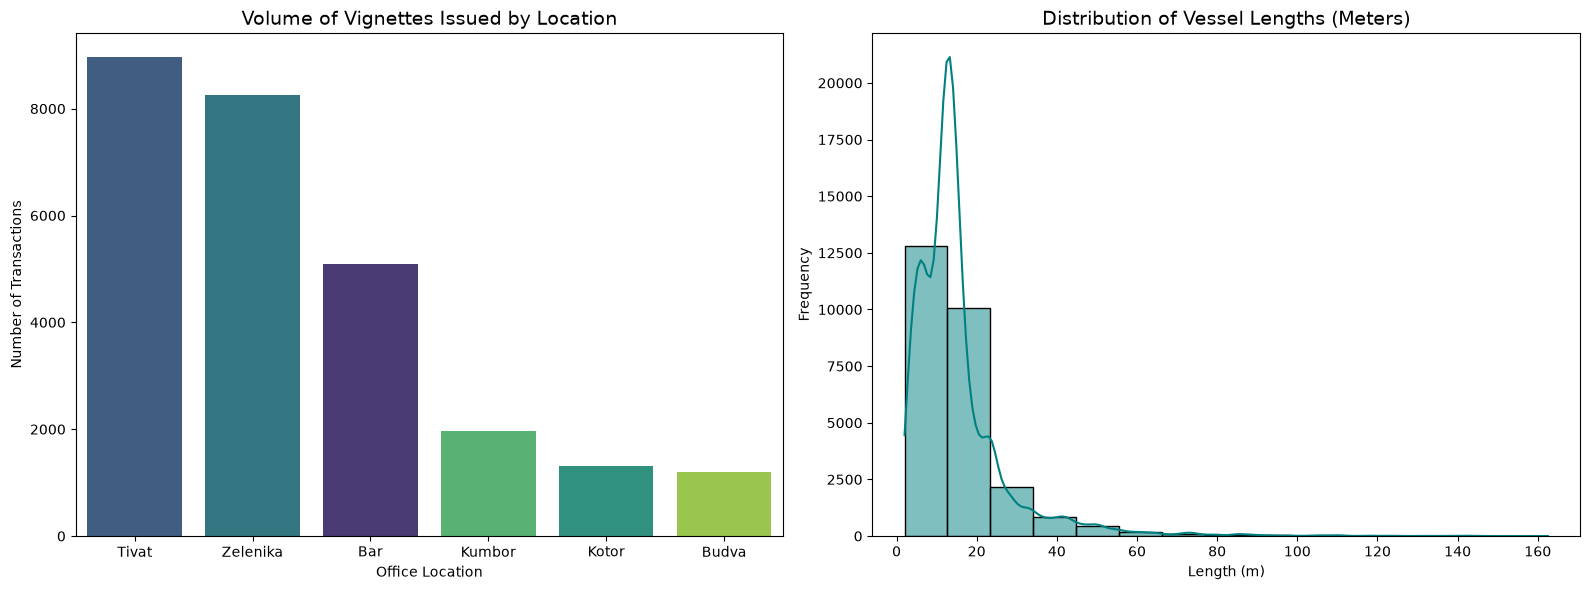

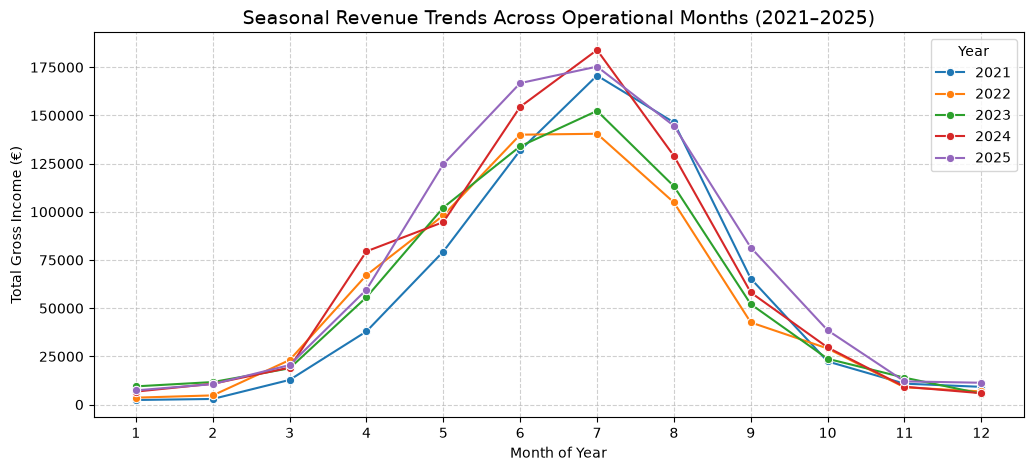

In [16]:
# Set up a structured canvas for our primary insights
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Volume of Vignettes Issued by Location
sns.countplot(ax=axes[0], data=df, x='Issued by', hue='Issued by', order=df['Issued by'].value_counts().index, palette='viridis', legend=False)
axes[0].set_title('Volume of Vignettes Issued by Location', fontsize=14)
axes[0].set_xlabel('Office Location')
axes[0].set_ylabel('Number of Transactions')

# Plot 2: Distribution of Vessel Lengths
sns.histplot(ax=axes[1], data=df, x='Length of the vessel', bins=15, kde=True, color='teal')
axes[1].set_title('Distribution of Vessel Lengths (Meters)', fontsize=14)
axes[1].set_xlabel('Length (m)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Plot 3: Seasonal Revenue Trends Across Years (Filtered to exclude incomplete 2026 data)
df_filtered = df[df['Year'] < 2026]
monthly_trend = df_filtered.groupby(['Year', 'Month'])['Total price €'].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_trend, x='Month', y='Total price €', hue='Year', marker='o', palette='tab10')
plt.title('Seasonal Revenue Trends Across Operational Months (2021–2025)', fontsize=14)
plt.xlabel('Month of Year')
plt.ylabel('Total Gross Income (€)')
plt.xticks(range(1, 13))
plt.legend(title='Year')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


---

### **Time Series Resampling & Moving Average Trend Analysis**

> To analyze daily revenue momentum and filter out short-term market noise, we apply temporal resampling and rolling statistical smoothing:
> * `resample('D')`: Takes all transaction dates and sums up the revenue for each individual day of the year to create a clean, continuous time series.
> * `rolling(window=30)`: Computes the average revenue over the past 30 days for each day on the chart. This creates a smooth trendline that tracks overall performance while filtering out minor daily fluctuations.
> * **Multi-Layer Plotting Structure:**
>> * **First line (`skyblue`, thin):** Displays raw daily revenue values, acting as the background oscillation and capturing daily volatility.
>> * **Second line (`darkblue`, thicker):** Represents the smooth 30-day moving average trend, highlighting the structural direction of revenue over time.
>
>
>
>

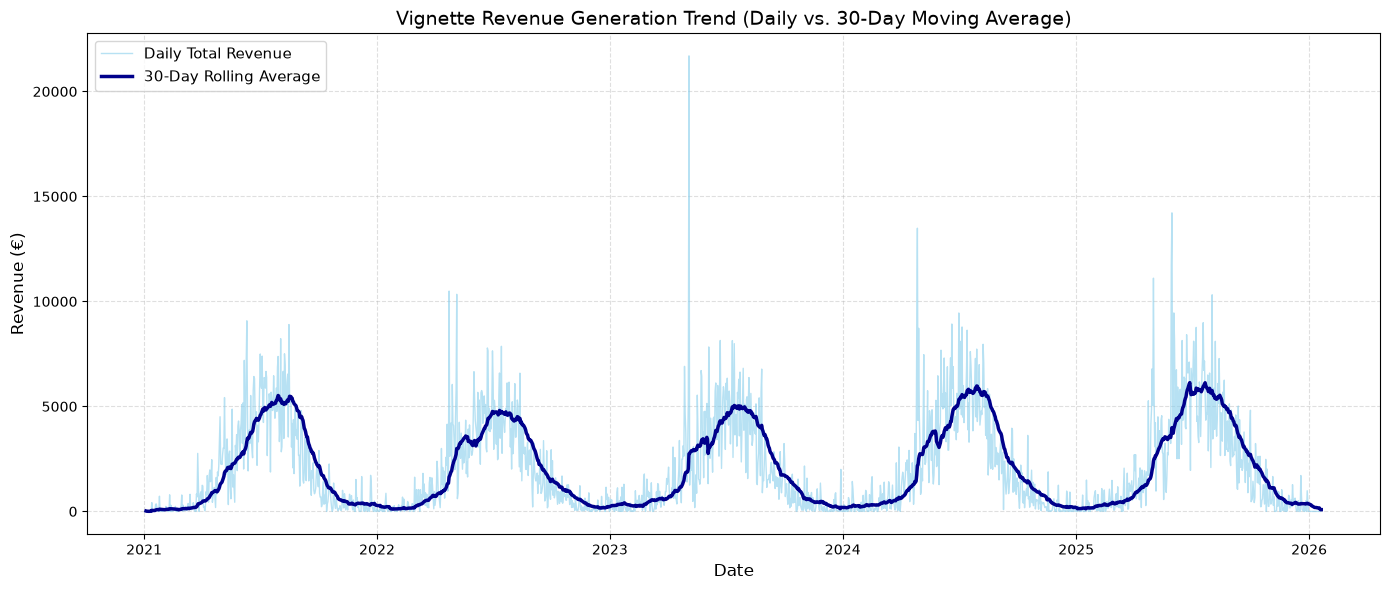

In [17]:
# 1. Ensure 'Valid from' is in datetime format and sort the dataframe chronologically
df['Valid from'] = pd.to_datetime(df['Valid from'])
df_sorted = df.sort_values('Valid from').copy()

# 2. Group data by day to get the daily total revenue (or transaction counts)
daily_revenue = df_sorted.set_index('Valid from')['Total price €'].resample('D').sum().reset_index()

# 3. Calculate a 30-day rolling average (moving average) to smooth out short-term fluctuations
daily_revenue['Rolling_Average'] = daily_revenue['Total price €'].rolling(window=30, min_periods=1).mean()

# 4. Set up the figure size for the time-series plot
plt.figure(figsize=(14, 6))

# 5. Plot the raw daily values with a thinner, lighter line (mimicking the background daily average in Image 1)
plt.plot(
    daily_revenue['Valid from'],
    daily_revenue['Total price €'],
    color='skyblue',
    alpha=0.6,
    linewidth=1,
    label='Daily Total Revenue'
)

# 6. Plot the smooth 30-day rolling average with a darker, bolder line (mimicking the smooth trend line in Image 1)
plt.plot(
    daily_revenue['Valid from'],
    daily_revenue['Rolling_Average'],
    color='darkblue',
    linewidth=2.5,
    label='30-Day Rolling Average'
)

# 7. Add titles, labels, legend, and gridlines
plt.title('Vignette Revenue Generation Trend (Daily vs. 30-Day Moving Average)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Revenue (€)', fontsize=12)
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


---

### **Simple and Clear Seasonal Revenue Analysis**

> This chart groups the dataset by year and season, displaying total revenue on the vertical axis and chronological seasons on the horizontal axis. By comparing lines across multiple years, it clearly illustrates seasonal performance spikes and revenue patterns.

*(Овај графикон групеше податке по годинама и сезонама, приказујући укупан приход на вертикалној оси и хрoнолошке сезоне на хоризонталној оси. Упоређивањем линија кроз више година, јасно илуструје сезонске скокове перформанси и обрасце прихода).*

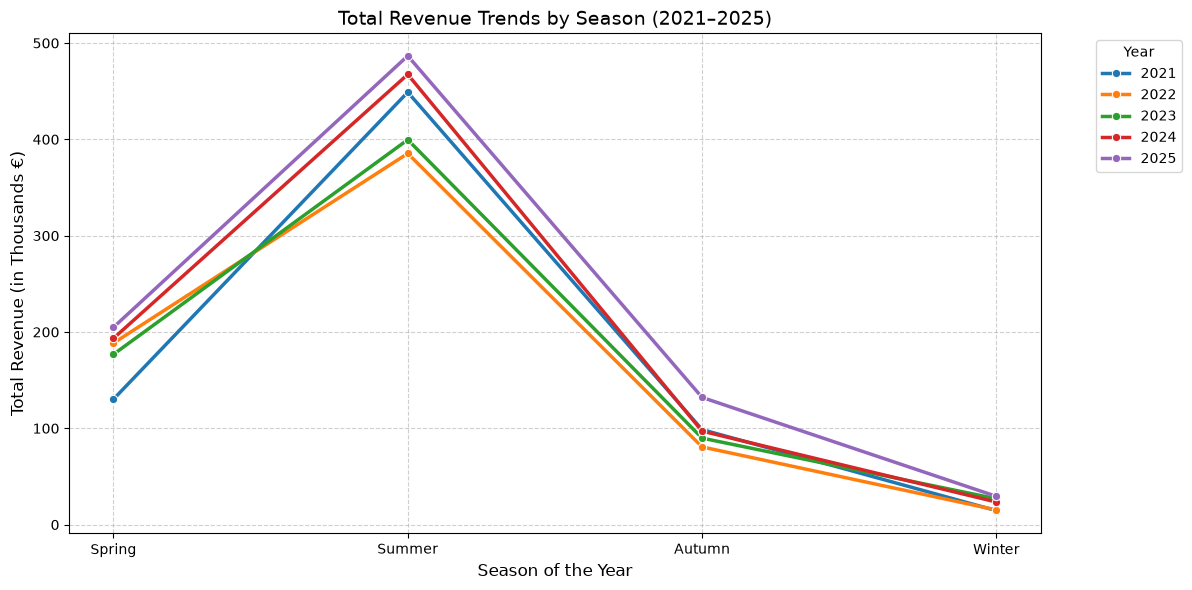

In [18]:
# --- Seasonal Revenue Trends by Season (Fixed Chart) ---
# 1. Filter out 2026 and scale revenue to thousands of euros
df_filtered = df[df['Year'] < 2026].copy()
df_filtered['Revenue_in_Thousands'] = df_filtered['Total price €'] / 1000.0

# 2. Group data by Year and Season, then sum up the revenue
seasonal_trend = df_filtered.groupby(['Year', 'Season'])['Revenue_in_Thousands'].sum().reset_index()

# 3. Define chronological order and convert 'Season' to a categorical type with that specific order
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']
seasonal_trend['Season'] = pd.Categorical(seasonal_trend['Season'], categories=season_order, ordered=True)

# 4. Sort the DataFrame so lines connect correctly in chronological order
seasonal_trend = seasonal_trend.sort_values(['Year', 'Season'])

# 5. Set up the figure size
plt.figure(figsize=(12, 6))

# 6. Create the line plot with Seasons on the X-axis and Years as separate lines (hue)
sns.lineplot(
    data=seasonal_trend,
    x='Season',
    y='Revenue_in_Thousands',
    hue='Year',
    marker='o',
    palette='tab10',
    linewidth=2.5
)

# 7. Add titles, labels, legend, and gridlines
plt.title('Total Revenue Trends by Season (2021–2025)', fontsize=14)
plt.xlabel('Season of the Year', fontsize=12)
plt.ylabel('Total Revenue (in Thousands €)', fontsize=12)
plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


---

### **Stacked Bar Chart by Location**

> This chart clearly displays how transaction volumes or revenues changed year-over-year for each specific office location (`Issued by`).

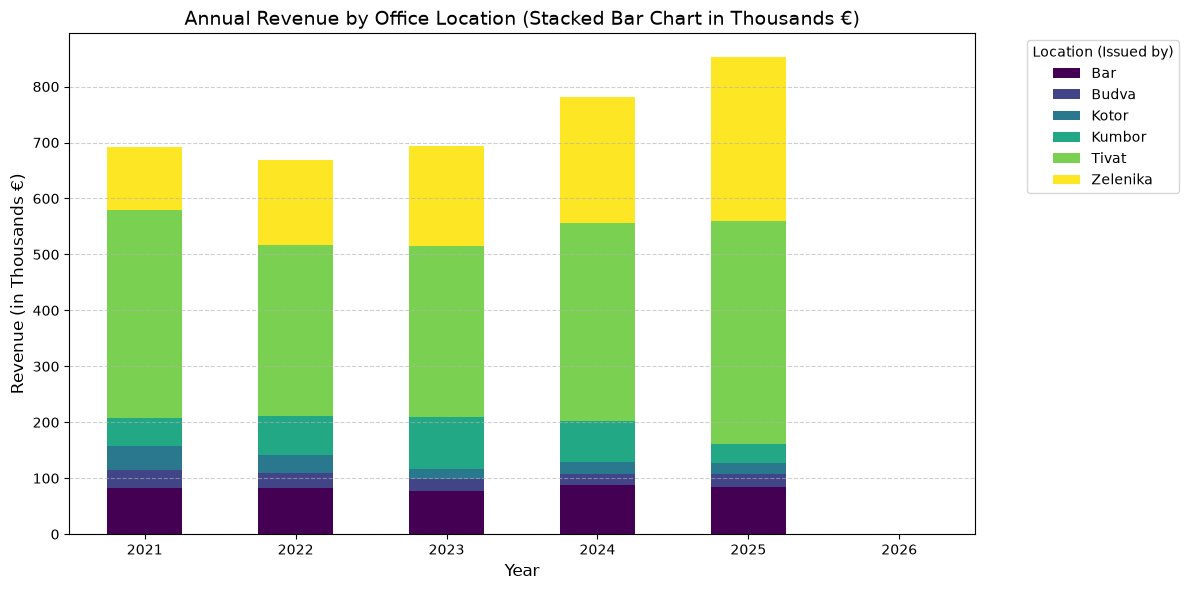

In [19]:
# 1. Create a pivot table: rows are Years, columns are Locations (Issued by), values are total revenue
location_year_pivot = df.pivot_table(
    index='Year',
    columns='Issued by',
    values='Total price €',
    aggfunc='sum'
).fillna(0) / 1000.0  # Fill missing values with 0 and scale values to thousands of euros

# 2. Plot the pivot table as a stacked bar chart
ax = location_year_pivot.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')

# 3. Add titles and formatting labels
plt.title('Annual Revenue by Office Location (Stacked Bar Chart in Thousands €)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Revenue (in Thousands €)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Location (Issued by)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### **Geospatial Revenue Distribution Map (Plotly)**
>To complement our bar charts with spatial context, we map total gross revenue and transaction volume across all six regional port branch offices along the Montenegrin coast (`Tivat`, `Zelenika`, `Bar`, `Kumbor`, `Kotor`, and `Budva`). Circle sizes and color intensities scale proportionally with each port's total revenue, while interactive popups display exact operational metrics.

In [20]:
# 1. Define exact geographic coordinates (latitude, longitude) for each port branch
port_coords = pd.DataFrame({
    'Issued by': ['Tivat', 'Zelenika', 'Bar', 'Kumbor', 'Kotor', 'Budva'],
    'lat': [42.4342, 42.4485, 42.0931, 42.4383, 42.4247, 42.2864],
    'lon': [18.6936, 18.5736, 19.0886, 18.5919, 18.7712, 18.8400]
})

# 2. Aggregate revenue, transaction count, and average vessel length per port
port_summary = df.groupby('Issued by').agg(
    Total_Revenue=('Total price €', 'sum'),
    Total_Transactions=('Vignette serial number', 'count'),
    Avg_Length=('Length of the vessel', 'mean')
).reset_index()

# 3. Merge operational metrics with coordinates
map_df = pd.merge(port_summary, port_coords, on='Issued by')

# 4. Create an interactive map of the Montenegrin coast (works natively in Colab without API keys)
fig = px.scatter_map(
    map_df,
    lat='lat',
    lon='lon',
    size='Total_Revenue',
    color='Total_Revenue',
    hover_name='Issued by',
    hover_data={
        'lat': False,
        'lon': False,
        'Total_Revenue': ':,.2f',
        'Total_Transactions': ':,',
        'Avg_Length': ':.1f'
    },
    color_continuous_scale='Teal',
    size_max=45,
    zoom=9.2,
    center={'lat': 42.28, 'lon': 18.82},
    map_style='carto-positron',
    title='Geospatial Distribution of Vignette Revenue Across Montenegrin Ports (€)'
)

fig.update_layout(height=550, margin={'r': 0, 't': 50, 'l': 0, 'b': 0})
fig.show()

NameError: name 'px' is not defined


---

### **Key EDA Findings & Business Insights**

> * **Revenue Concentration**: Tivat port branch clearly dominates the operations, generating nearly 47% of the total gross revenue.
> * **Seasonal Demand**: Revenue and transaction volume experience a sharp, predictable surge during the summer peak season (June to August).
> * **Vessel Profile**: The vast majority of registered vessels fall into the length range between 8 and 17 meters, representing standard recreational yachts and boats in local marinas.
>
>

In [ ]:
from pathlib import Path

data_dir = Path("../data/clean/") if Path.cwd().name == "notebooks" else Path("data")
data_dir.mkdir(parents=True, exist_ok=True)
df.to_pickle(data_dir / "clean_data.pkl")
